Name:Yash P. Kherde        
Roll No. : 29
CSE(DS)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

In [2]:
%pip install kagglehub

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [3]:
import kagglehub
import os

path = kagglehub.dataset_download("arezaei81/heartcsv")

for root, dirs, files in os.walk(path):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

C:\Users\yashk\.cache\kagglehub\datasets\arezaei81\heartcsv\versions\1\heart.csv


In [4]:
csv_file = next(
    os.path.join(root, file)
    for root, dirs, files in os.walk(path)
    for file in files
    if file.endswith(".csv")
)

df = pd.read_csv(csv_file)

print("Dataset Shape:", df.shape)
display(df.head())
df.info()

Dataset Shape: (1025, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [5]:
print("Missing Values:\n", df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())

df = df.drop_duplicates()

X = df.drop("target", axis=1)
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Missing Values:
 age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Duplicate Rows: 723
Training Data: (241, 13)
Testing Data: (61, 13)


In [6]:
svm_model = SVC(kernel="linear", C=1.0, probability=True, random_state=42)

svm_model.fit(X_train, y_train)

y_pred = svm_model.predict(X_test)

print("Support Vector Machine Model Trained Successfully!")

Support Vector Machine Model Trained Successfully!


In [7]:
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.8197
Precision: 0.8056
Recall: 0.8788
F1 Score: 0.8406

Classification Report:

              precision    recall  f1-score   support

           0       0.84      0.75      0.79        28
           1       0.81      0.88      0.84        33

    accuracy                           0.82        61
   macro avg       0.82      0.81      0.82        61
weighted avg       0.82      0.82      0.82        61



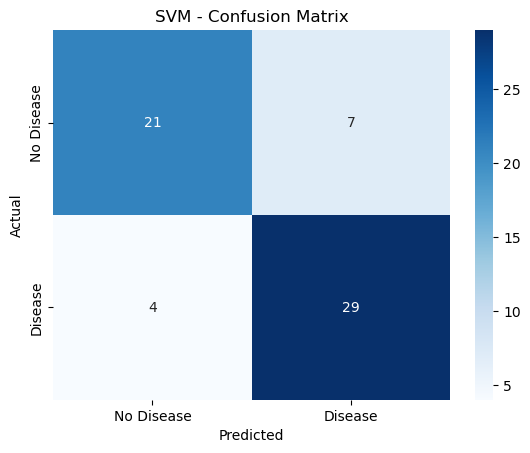

In [8]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVM - Confusion Matrix")
plt.show()

    Actual  Predicted
0        0          0
1        0          1
2        0          0
3        0          1
4        0          1
5        0          0
6        1          1
7        0          0
8        1          1
9        0          1
10       1          1
11       1          1
12       0          1
13       1          1
14       1          0


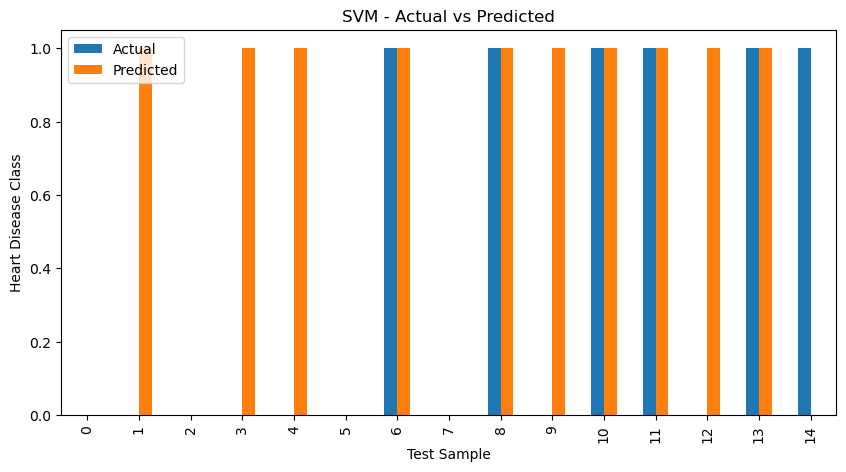

In [9]:
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print(results.head(15))

results.head(15).plot(kind="bar", figsize=(10, 5))

plt.title("SVM - Actual vs Predicted")
plt.xlabel("Test Sample")
plt.ylabel("Heart Disease Class")
plt.legend(["Actual", "Predicted"])
plt.show()

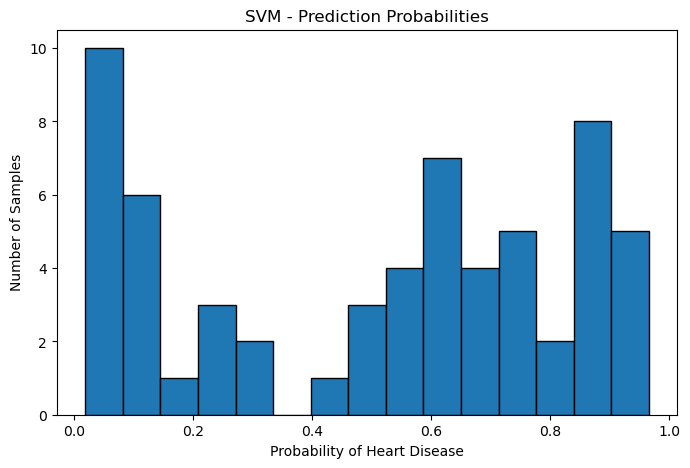

In [10]:
y_prob = svm_model.predict_proba(X_test)[:, 1]

plt.figure(figsize=(8, 5))
plt.hist(y_prob, bins=15, edgecolor="black")

plt.title("SVM - Prediction Probabilities")
plt.xlabel("Probability of Heart Disease")
plt.ylabel("Number of Samples")
plt.show()

In [11]:
print("Support Vector Machine Algorithm Analysis Completed Successfully.")
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))

Support Vector Machine Algorithm Analysis Completed Successfully.
Accuracy: 81.97 %
Precision: 0.8056
Recall: 0.8788
F1 Score: 0.8406
